# **Lab 8 - Edge Detection**

### By: Dr. Irfan  

### Mohammed Naif Alhadi - 2240007563 - 7MA2

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Butterfly.jpg'
img = cv2.imread(imgFile)

if img is None:
    raise FileNotFoundError(f"Could not load image: {imgFile}")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Normalize gradient magnitudes for display
def normalize_edges(edges):
    return cv2.normalize(
        edges, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

# Display the original image and an edge map
def show_edges(edges, title, cmap='gray'):
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(edges, cmap=cmap, vmin=0, vmax=255)
    plt.title(title)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

## **Sobel Edge Detector**

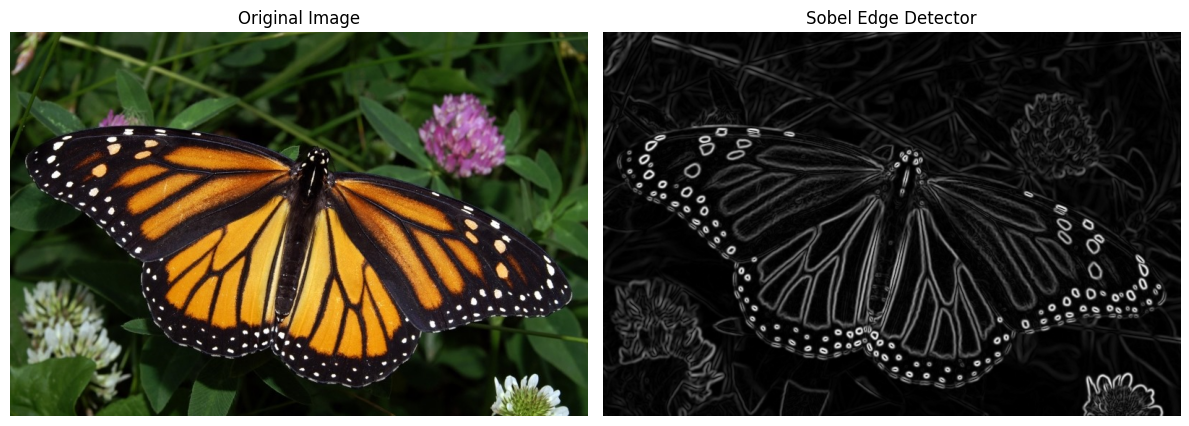

In [16]:
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel_edges = normalize_edges(sobel_magnitude)

show_edges(sobel_edges, 'Sobel Edge Detector')

# **Robert Edge Detector**

### Comparing to Sobel
   
Roberts: Kernel Size  -->    2x2
Sobel:   Kernel Size  -->    3x3

Roberts: Speed  --> Faster
Sobel:   Speed  --> Slower

Roberts: Noise Resistance  --> Poor (High Senstivity)
Sobel:   Noise Resistnace  --> Good (Built-in Smoothing)

Roberts: Edge Width  --> Very thin/sharp
Sobel:   Edge Width  --> Thicker

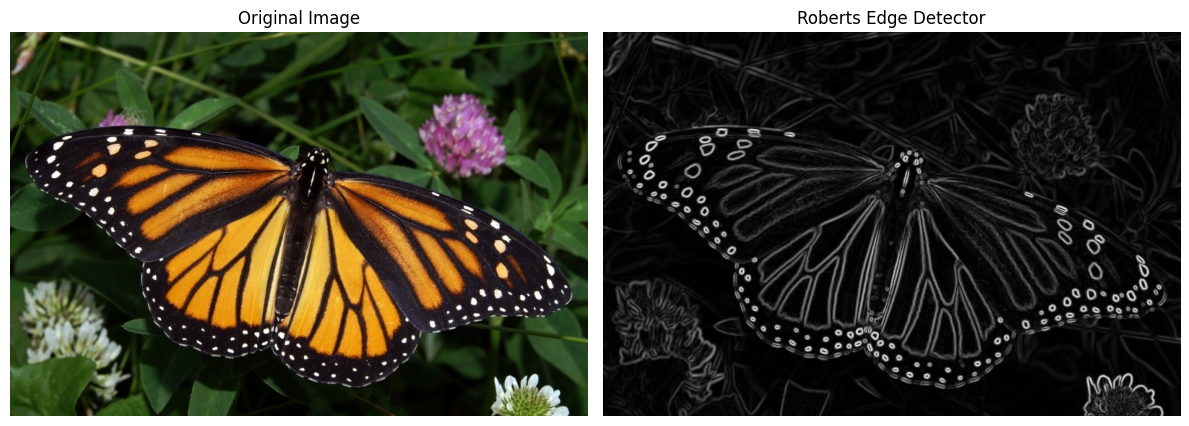

In [17]:
kernel_x = np.array([
    [1, 0],
    [0, -1]
], dtype=np.float64)

kernel_y = np.array([
    [0, 1],
    [-1, 0]
], dtype=np.float64)

# Use the blurred image because Roberts is sensitive to noise
roberts_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
roberts_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

roberts_magnitude = cv2.magnitude(roberts_x, roberts_y)
roberts_edges = normalize_edges(roberts_magnitude)

show_edges(roberts_edges, 'Roberts Edge Detector')

## **Prewitt Edge Detector**

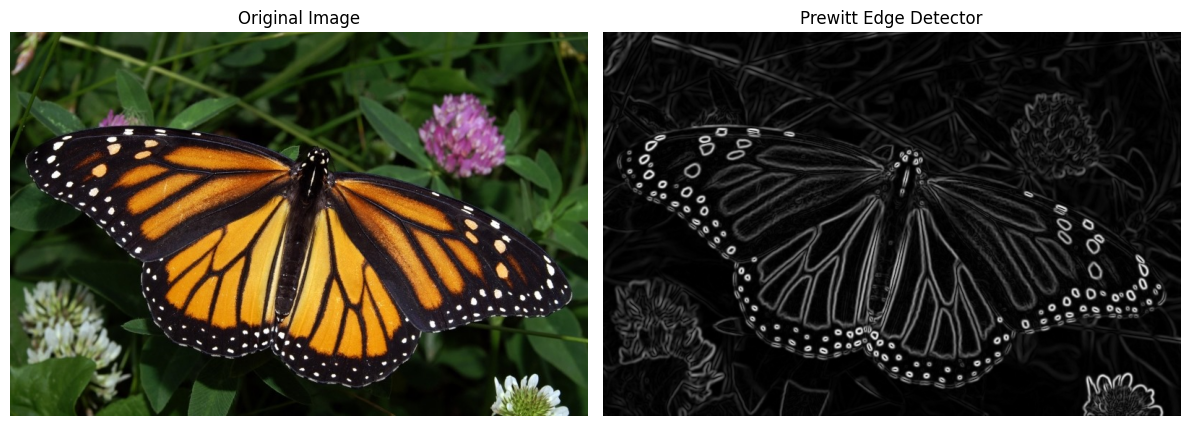

In [18]:
kernel_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float64)

kernel_y = np.array([
    [-1, -1, -1],
    [0, 0, 0],
    [1, 1, 1]
], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

prewitt_magnitude = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_edges = normalize_edges(prewitt_magnitude)

show_edges(prewitt_edges, 'Prewitt Edge Detector')

## **Canny Edge Detector**

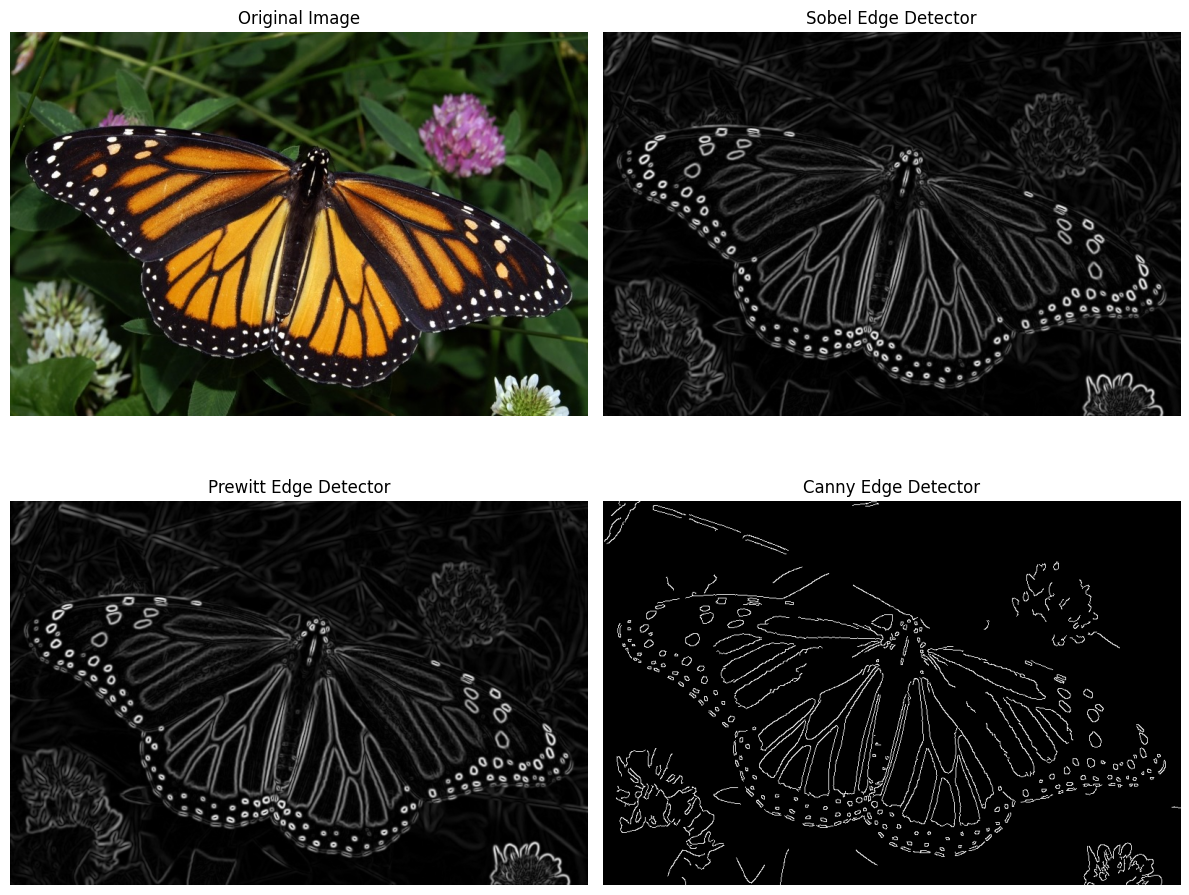

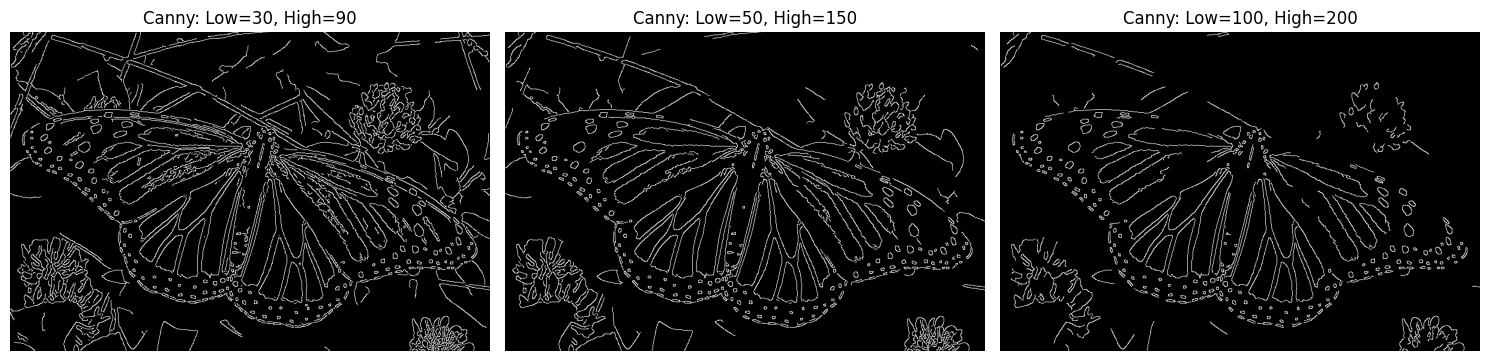

In [19]:
canny_edges = cv2.Canny(blurred, 100, 200)

# Task 1: Original image and the three required edge maps
results = [
    ('Original Image', cv2.cvtColor(img, cv2.COLOR_BGR2RGB)),
    ('Sobel Edge Detector', sobel_edges),
    ('Prewitt Edge Detector', prewitt_edges),
    ('Canny Edge Detector', canny_edges)
]

plt.figure(figsize=(12, 10))

for i, (title, result) in enumerate(results):
    plt.subplot(2, 2, i + 1)

    if result.ndim == 3:
        plt.imshow(result)
    else:
        plt.imshow(result, cmap='gray', vmin=0, vmax=255)

    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Task 2: Compare the required Canny thresholds
threshold_pairs = [(30, 90), (50, 150), (100, 200)]

plt.figure(figsize=(15, 5))

for i, (low, high) in enumerate(threshold_pairs):
    edges = cv2.Canny(blurred, low, high)

    plt.subplot(1, 3, i + 1)
    plt.imshow(edges, cmap='gray', vmin=0, vmax=255)
    plt.title(f'Canny: Low={low}, High={high}')
    plt.axis('off')

plt.tight_layout()
plt.show()

## **Multi-Channel Canny Edge Detector**

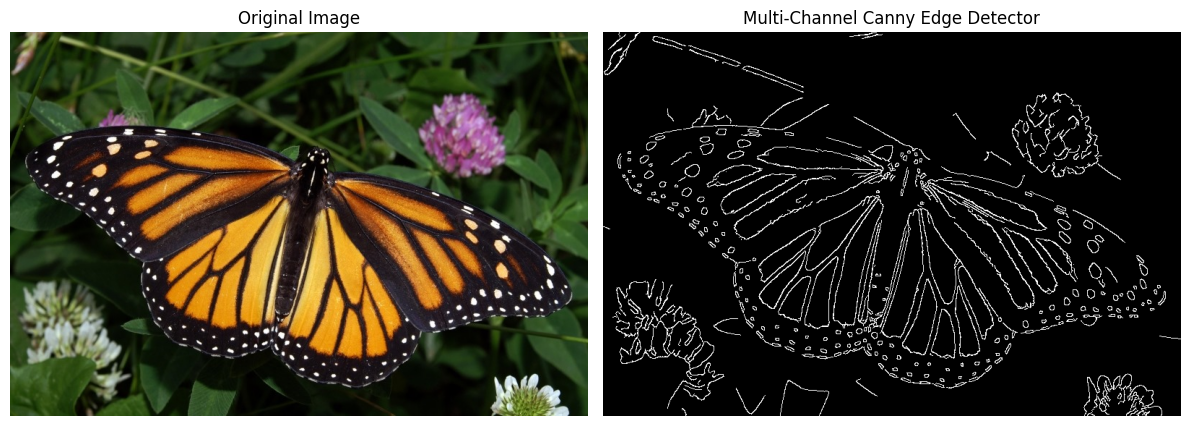

In [20]:
b, g, r = cv2.split(img)

# Apply Canny separately to each color channel
channel_edges = []

for channel in (b, g, r):
    channel_blurred = cv2.GaussianBlur(channel, (5, 5), 0)
    edges = cv2.Canny(channel_blurred, 100, 200)
    channel_edges.append(edges)

# Keep edges detected in any channel
multi_canny = cv2.bitwise_or(channel_edges[0], channel_edges[1])
multi_canny = cv2.bitwise_or(multi_canny, channel_edges[2])

show_edges(multi_canny, 'Multi-Channel Canny Edge Detector')

## **LoG Filter**

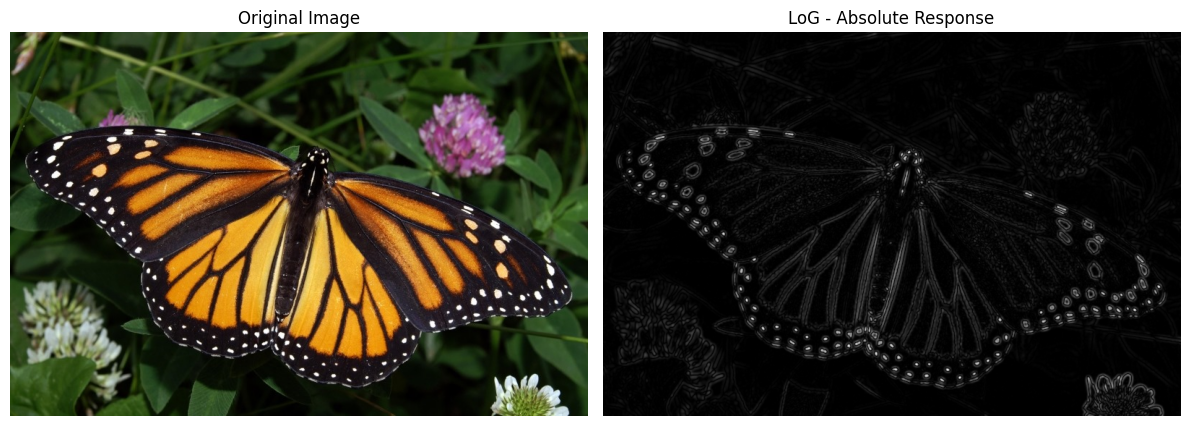

In [21]:
# Gaussian smoothing followed by the Laplacian
laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=5)

# Display the absolute response
log_edges = normalize_edges(np.abs(laplacian))

show_edges(log_edges, 'LoG - Absolute Response')

## **DoG Filter**

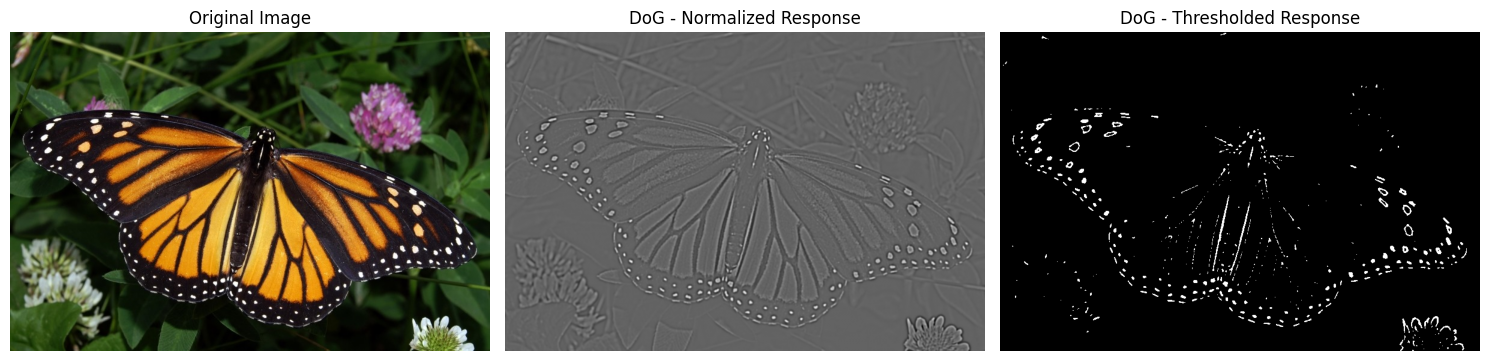

In [22]:
# Use floating-point input to preserve precision
gray_float = gray.astype(np.float32)

blur_narrow = cv2.GaussianBlur(gray_float, (0, 0), sigmaX=1.0)
blur_wide = cv2.GaussianBlur(gray_float, (0, 0), sigmaX=2.0)

dog = blur_narrow - blur_wide
dog_normalized = normalize_edges(dog)

_, dog_binary = cv2.threshold(
    dog_normalized, 127, 255, cv2.THRESH_BINARY
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(dog_normalized, cmap='gray', vmin=0, vmax=255)
plt.title('DoG - Normalized Response')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(dog_binary, cmap='gray', vmin=0, vmax=255)
plt.title('DoG - Thresholded Response')
plt.axis('off')

plt.tight_layout()
plt.show()

## **Gradient Edge Detector for Colored Images**

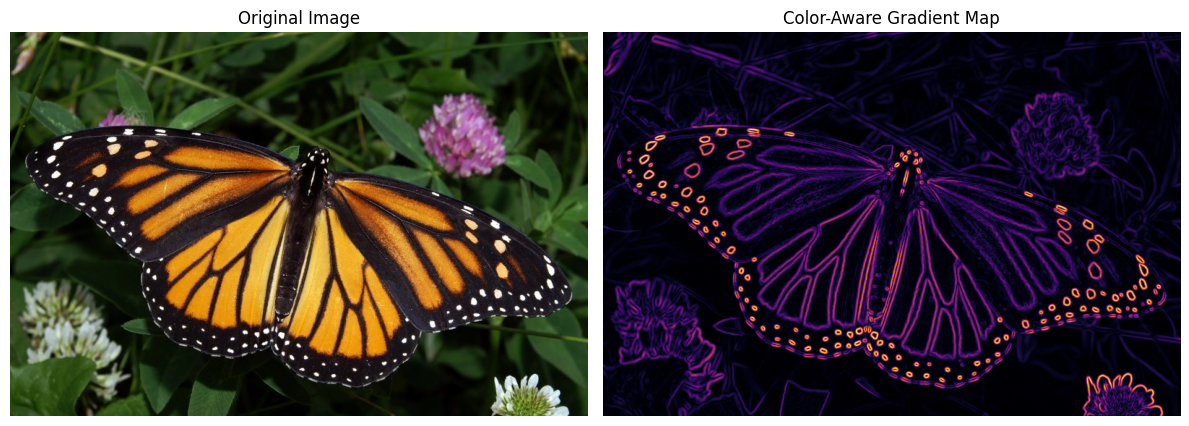

In [23]:
b, g, r = cv2.split(img)

def get_channel_gradient(channel):
    channel_blurred = cv2.GaussianBlur(channel, (3, 3), 0)

    gx = cv2.Sobel(channel_blurred, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(channel_blurred, cv2.CV_64F, 0, 1, ksize=3)

    return cv2.magnitude(gx, gy)

grad_b = get_channel_gradient(b)
grad_g = get_channel_gradient(g)
grad_r = get_channel_gradient(r)

combined_gradient = np.sqrt(
    grad_b**2 + grad_g**2 + grad_r**2
)

color_edges = normalize_edges(combined_gradient)

show_edges(color_edges, 'Color-Aware Gradient Map', cmap='inferno')